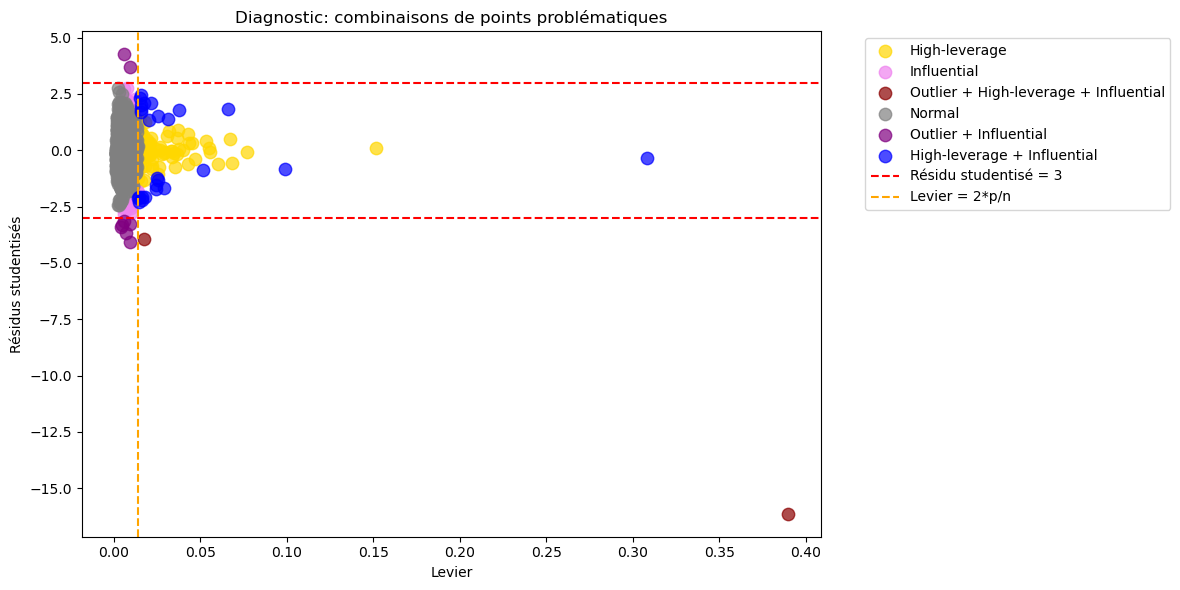

In [46]:
import statsmodels.api as sm
import matplotlib.pyplot as plt
import numpy as np


influence = mon_modele.get_influence()
summary_frame = influence.summary_frame()

# Mesures
resid_student = influence.resid_studentized_external
leverage = summary_frame['hat_diag']
cooks_d = summary_frame['cooks_d']

# Seuils
n, p = X_multi.shape
outlier_threshold = 3
leverage_threshold = 2 * p / n
cooks_threshold = 4 / n

# Détection des catégories
is_outlier = abs(resid_student) > outlier_threshold
is_high_lev = leverage > leverage_threshold
is_influential = cooks_d > cooks_threshold

# Attribution des couleurs selon combinaisons
colors = []
labels = []

for o, h, i in zip(is_outlier, is_high_lev, is_influential):
    if o and h and i:
        colors.append('darkred')
        labels.append('Outlier + High-leverage + Influential')
    elif o and h:
        colors.append('orange')
        labels.append('Outlier + High-leverage')
    elif o and i:
        colors.append('purple')
        labels.append('Outlier + Influential')
    elif h and i:
        colors.append('blue')
        labels.append('High-leverage + Influential')
    elif o:
        colors.append('red')
        labels.append('Outlier')
    elif h:
        colors.append('gold')
        labels.append('High-leverage')
    elif i:
        colors.append('violet')
        labels.append('Influential')
    else:
        colors.append('gray')
        labels.append('Normal')

# Graphique
plt.figure(figsize=(12,6))
for c, lbl in set(zip(colors, labels)):
    idx = [j for j, l in enumerate(labels) if l == lbl]
    plt.scatter(leverage[idx], resid_student[idx], c=c, s=80, alpha=0.7, label=lbl)

plt.axhline(y=outlier_threshold, color='red', linestyle='--', label='Résidu studentisé = 3')
plt.axhline(y=-outlier_threshold, color='red', linestyle='--')
plt.axvline(x=leverage_threshold, color='orange', linestyle='--', label='Levier = 2*p/n')
plt.xlabel("Levier")
plt.ylabel("Résidus studentisés")
plt.title("Diagnostic: combinaisons de points problématiques")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

